# California House Price Prediction: End-to-End Data Science Workflow

**Goal:** predict the median house value of a California census block group, compare a
least-squares **Linear Regression** with tree ensembles (**Random Forest**, **XGBoost** on the GPU),
validate them properly, and interpret the results, errors and ethical risks.

| Brief requirement | Section |
|---|---|
| Data acquisition, source details | 1 |
| Data-quality assessment | 2 |
| Train-test split (done early to avoid leakage) | 3 |
| Missing-value treatment (compared with evidence) | 4 |
| Univariate EDA | 5 |
| Bivariate EDA, correlation analysis | 6 |
| Outlier identification (IQR vs Isolation Forest) | 7 |
| Feature engineering, categorical encoding | 8 |
| Least-squares optimisation (hand-solved vs sklearn), OLS inference | 9 |
| Regression models and tuning (GPU) | 10 |
| K-fold CV, MAE/RMSE/R², method comparison, spatial validation | 11 |
| Residual analysis | 12 |
| Important predictors | 13 |
| Error of the chained app | 14 |
| Limitations and ethics | 15 |
| Dashboard / decision summary | 16 |

> Run `Trainer_helper_model.ipynb` first. Section 14 uses the helper models it saves.

In [1]:
import json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import joblib
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import KFold, GroupKFold, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

from housing_features import (TARGET, NUMERIC, RAW_NUMERIC, CATEGORICAL, ENGINEERED,
                              add_engineered_features, make_pipeline, split_data, get_xgb_device)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

FIG, MODELS, REPORTS = Path("figures"), Path("models"), Path("reports")
for p in (FIG, MODELS, REPORTS):
    p.mkdir(exist_ok=True)

# ---- consistent chart style -------------------------------------------------------
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#a32b2b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
usd = mticker.FuncFormatter(lambda v, _: f"${v/1000:,.0f}k")

def savefig(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred)}

DEVICE = get_xgb_device()
print("XGBoost training device:", DEVICE)

XGBoost training device: cuda


## 1. Data acquisition

**Dataset:** *California Housing* (file `housing.csv`, 20,640 rows × 10 columns).

* **Origin:** 1990 U.S. Census, compiled by R. Kelley Pace and Ronald Barry,
  *"Sparse Spatial Autoregressions"*, Statistics & Probability Letters 33 (1997) 291–297.
  Distributed through the StatLib repository (Carnegie Mellon University).
* **This version** (with the categorical `ocean_proximity` column and 207 deliberately removed
  `total_bedrooms` values) is the one published with A. Géron's *Hands-On Machine Learning*
  and mirrored on Kaggle (`camnugent/california-housing-prices`).
* **Unit of observation:** one **census block group**, typically 600–3,000 people. It is *not*
  a single house. `total_rooms`, `population` etc. are block totals; `median_income` is in
  tens of thousands of USD; `median_house_value` (the target) is in USD.

In [2]:
data = pd.read_csv("housing.csv")
print(data.shape)
display(data.head())
data.dtypes.to_frame("dtype").T

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,object


## 2. Data-quality assessment

We check completeness, duplicates, valid ranges, rare categories and **censoring**, i.e. values
that were capped by the original data collectors.

In [3]:
quality = pd.DataFrame({
    "missing": data.isna().sum(),
    "missing_%": data.isna().mean() * 100,
    "unique": data.nunique(),
    "min": data.min(numeric_only=True),
    "max": data.max(numeric_only=True),
})
print("Duplicate rows:", data.duplicated().sum())
print("Non-positive counts:", int((data[["total_rooms", "households", "population"]] <= 0).sum().sum()))
quality

Duplicate rows: 0
Non-positive counts: 0


,missing,missing_%,unique,min,max
households,0,0.000,1815,1.000,"6,082.000"
housing_median_age,0,0.000,52,1.000,52.000
latitude,0,0.000,862,32.540,41.950
longitude,0,0.000,844,-124.350,-114.310
median_house_value,0,0.000,3842,"14,999.000","500,001.000"
median_income,0,0.000,12928,0.500,15.000
ocean_proximity,0,0.000,5,NaN,NaN
population,0,0.000,3888,3.000,"35,682.000"
total_bedrooms,207,1.003,1923,1.000,"6,445.000"
total_rooms,0,0.000,5926,2.000,"39,320.000"


In [4]:
caps = pd.DataFrame({
    "column": ["median_house_value", "housing_median_age", "median_income"],
    "cap value": [data[TARGET].max(), data["housing_median_age"].max(), data["median_income"].max()],
})
caps["rows at cap"] = [int((data[c] >= v).sum()) for c, v in zip(caps["column"], caps["cap value"])]
caps["% of rows"] = caps["rows at cap"] / len(data) * 100
display(caps)
data["ocean_proximity"].value_counts().to_frame("rows")

,column,cap value,rows at cap,% of rows
0,median_house_value,"500,001.000",965,4.675
1,housing_median_age,52.000,1273,6.168
2,median_income,15.000,49,0.237


,rows
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


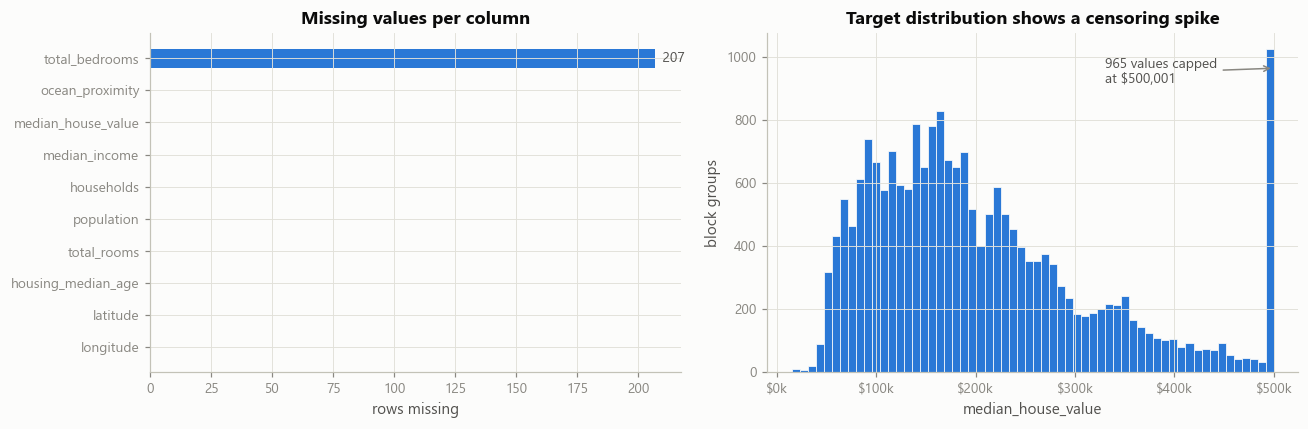

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
miss = data.isna().sum().sort_values()
axes[0].barh(miss.index, miss.values, color=BLUE, height=0.6)
axes[0].set_title("Missing values per column")
axes[0].set_xlabel("rows missing")
for i, v in enumerate(miss.values):
    if v:
        axes[0].text(v, i, f"  {v}", va="center", color=INK2, fontsize=9)

axes[1].hist(data[TARGET], bins=60, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
capped_n = int((data[TARGET] >= 500001).sum())
axes[1].annotate(f"{capped_n} values capped\nat $500,001", xy=(500001, capped_n), xytext=(330000, capped_n * 0.95),
                 color=INK2, fontsize=9, arrowprops=dict(arrowstyle="->", color=MUTED))
axes[1].xaxis.set_major_formatter(usd)
axes[1].set_title("Target distribution shows a censoring spike")
axes[1].set_xlabel("median_house_value"); axes[1].set_ylabel("block groups")
fig.tight_layout(); savefig(fig, "fig01_data_quality")

**Findings**

* Only `total_bedrooms` has missing values: 207 rows (1.0%). There are no duplicates and no
  impossible values.
* **Censoring:** 965 targets sit exactly at $500,001 (4.7%), and `housing_median_age` is capped
  at 52. `median_income` is also top-coded at 15.0001. A model cannot learn what lies above a cap,
  so predictions for expensive areas will be biased **downwards**. This is examined in §12.
* `ISLAND` has only 5 rows, too few to learn a reliable effect for that category.

## 3. Train-test split (done before any modelling decision)

We split **before** imputation, scaling or tuning, so that nothing learned from the test rows
leaks into the model. The split is stratified on income bands because income is the strongest
predictor, which keeps its distribution identical in both sets. All tuning and cross-validation
use the training set only. The test set is used **once**, for the final evaluation.

In [6]:
train_df, test_df = split_data(data)
X_train, y_train = train_df.drop(columns=TARGET), train_df[TARGET]
X_test, y_test = test_df.drop(columns=TARGET), test_df[TARGET]
print(f"train: {len(train_df):,} rows | test: {len(test_df):,} rows")
pd.DataFrame({"train mean": X_train[["median_income"]].mean(), "test mean": X_test[["median_income"]].mean()})

train: 16,512 rows | test: 4,128 rows


,train mean,test mean
median_income,3.876,3.850


## 4. Missing-value treatment: drop vs median imputation

We compare two strategies with 5-fold CV of the same Linear Regression pipeline:

* **A. Drop rows:** listwise deletion of the rows with missing `total_bedrooms`.
* **B. Median imputation inside the pipeline:** the median is learned on each training fold only.

In [7]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}
lr_pipe = make_pipeline(LinearRegression(), "linear")

complete = train_df.dropna()
res_drop = cross_validate(lr_pipe, complete.drop(columns=TARGET), complete[TARGET], cv=cv5, scoring=SCORING)
res_imp = cross_validate(lr_pipe, X_train, y_train, cv=cv5, scoring=SCORING)

pd.DataFrame({
    "rows used": [len(complete), len(train_df)],
    "CV RMSE": [-res_drop["test_RMSE"].mean(), -res_imp["test_RMSE"].mean()],
    "CV R2": [res_drop["test_R2"].mean(), res_imp["test_R2"].mean()],
}, index=["A. drop rows", "B. median impute"])

,rows used,CV RMSE,CV R2
A. drop rows,16354,"67,087.815",0.664
B. median impute,16512,"67,830.553",0.656


**Decision: B, median imputation inside the pipeline.** The CV RMSEs differ by only about 1%
(≈ $67.1k vs $67.8k), because only 1% of rows are affected. The two are not scored on identical
rows: A's folds simply exclude the 158 incomplete training rows. B keeps every row, and it can still score a **new**
property whose bedroom count is unknown, which dropping rows cannot. Because the imputer lives
inside the pipeline, it is re-learned on every training fold and never sees test data.
`total_bedrooms` is also ~0.93 correlated with `total_rooms`, so a regression imputer would be a
possible refinement.

## 5. Univariate EDA

In [8]:
desc = data[RAW_NUMERIC + [TARGET]].describe().T
desc["skew"] = data[RAW_NUMERIC + [TARGET]].skew()
desc

,count,mean,std,min,25%,50%,75%,max,skew
longitude,"20,640.000",-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310,-0.298
latitude,"20,640.000",35.632,2.136,32.540,33.930,34.260,37.710,41.950,0.466
housing_median_age,"20,640.000",28.639,12.586,1.000,18.000,29.000,37.000,52.000,0.060
total_rooms,"20,640.000","2,635.763","2,181.615",2.000,"1,447.750","2,127.000","3,148.000","39,320.000",4.147
total_bedrooms,"20,433.000",537.871,421.385,1.000,296.000,435.000,647.000,"6,445.000",3.460
population,"20,640.000","1,425.477","1,132.462",3.000,787.000,"1,166.000","1,725.000","35,682.000",4.936
households,"20,640.000",499.540,382.330,1.000,280.000,409.000,605.000,"6,082.000",3.410
median_income,"20,640.000",3.871,1.900,0.500,2.563,3.535,4.743,15.000,1.647
median_house_value,"20,640.000","206,855.817","115,395.616","14,999.000","119,600.000","179,700.000","264,725.000","500,001.000",0.978


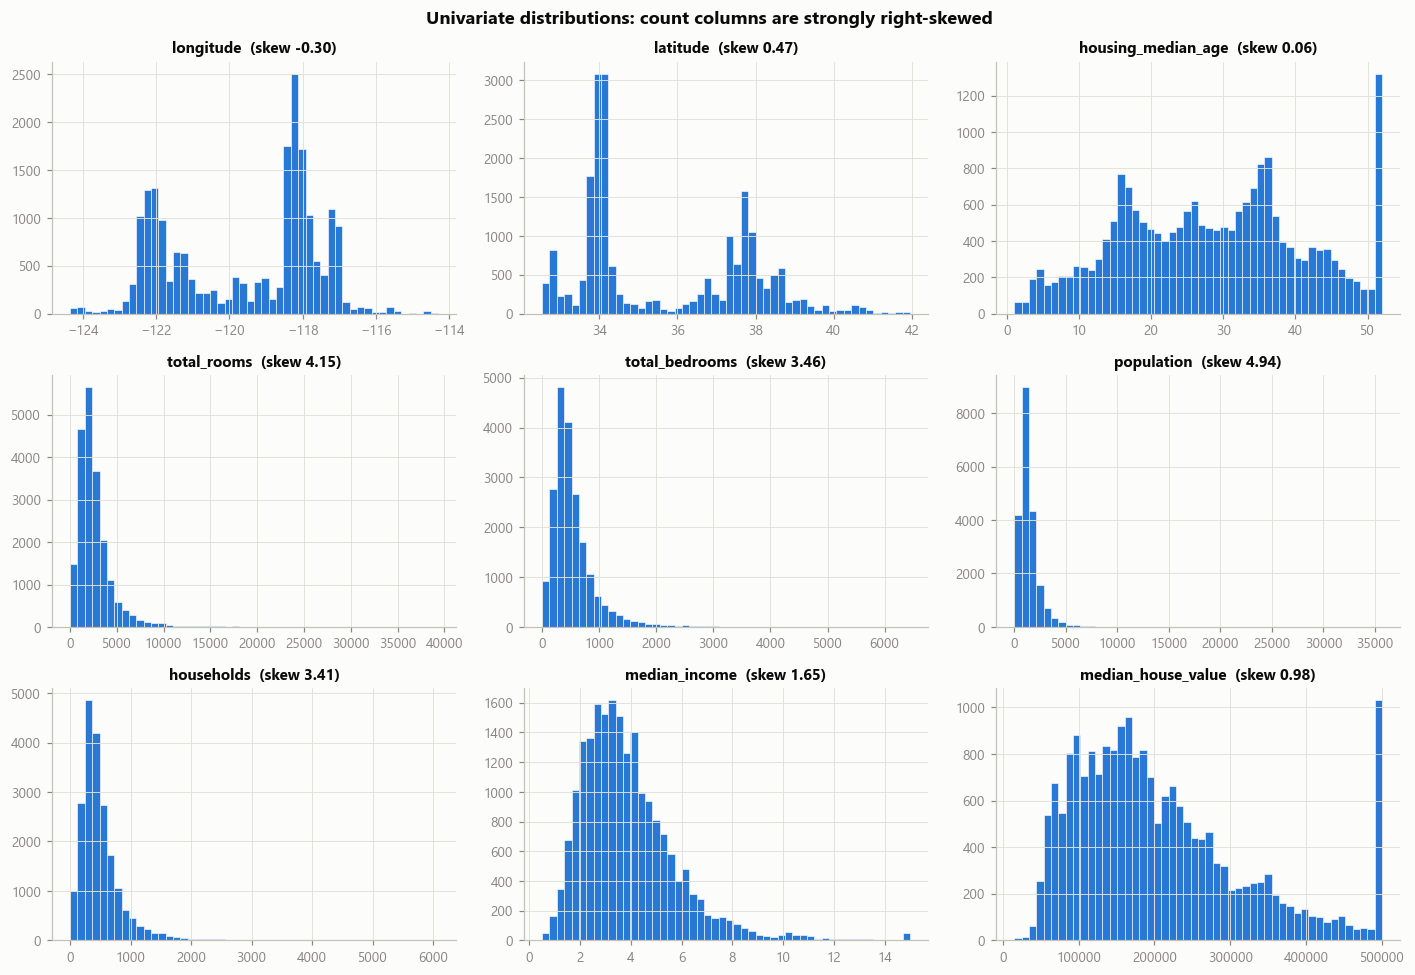

In [9]:
cols = RAW_NUMERIC + [TARGET]
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.flat, cols):
    ax.hist(data[c].dropna(), bins=50, color=BLUE, edgecolor="#fcfcfb", linewidth=0.4)
    ax.set_title(f"{c}  (skew {data[c].skew():.2f})", fontsize=10)
    ax.set_ylabel("")
fig.suptitle("Univariate distributions: count columns are strongly right-skewed", fontweight="bold", color=INK)
fig.tight_layout(); savefig(fig, "fig02_univariate_histograms")

* `total_rooms`, `total_bedrooms`, `population` and `households` have skew > 3 with long right
  tails (very large block groups). A **log transform** makes them closer to symmetric, which
  helps the linear model. Trees do not need it.
* `median_income` is moderately skewed. The target is bimodal-looking because of the cap.
* Latitude and longitude are bimodal: the Bay Area (~37.8° N) and Los Angeles (~34° N).

## 6. Bivariate EDA and correlation analysis

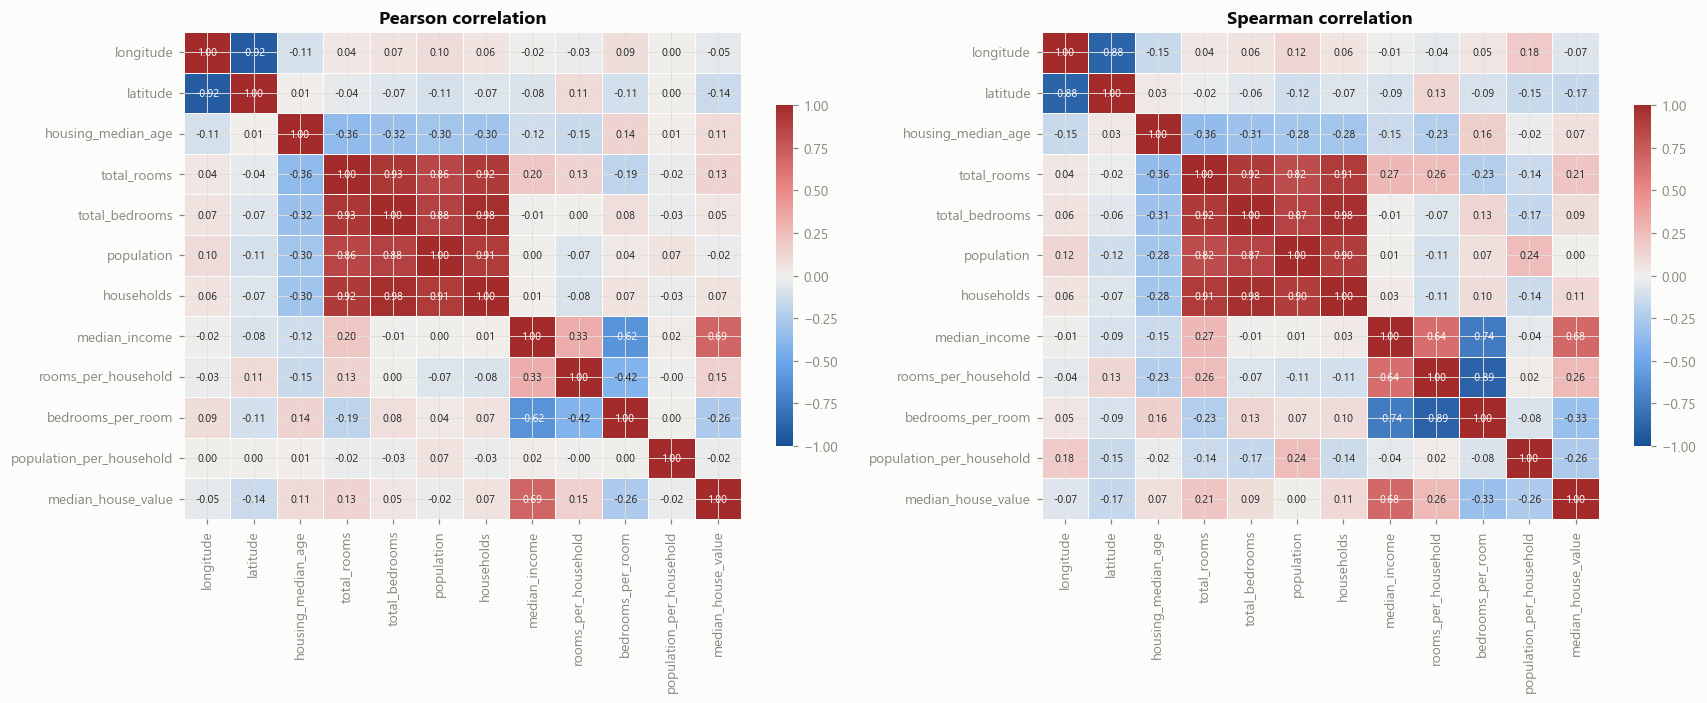

,pearson r with target
median_income,0.688
bedrooms_per_room,-0.256
rooms_per_household,0.152
latitude,-0.144
total_rooms,0.134
housing_median_age,0.106
households,0.066
total_bedrooms,0.050
longitude,-0.046
population,-0.025


In [10]:
corr_df = add_engineered_features(data)[NUMERIC + [TARGET]]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    c = corr_df.corr(method=method)
    sns.heatmap(c, ax=ax, cmap=DIV, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
                linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"shrink": 0.7})
    ax.set_title(f"{method.title()} correlation")
fig.tight_layout(); savefig(fig, "fig03_correlation_heatmaps")

corr_df.corr(method="pearson")[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("pearson r with target")

* **`median_income` dominates** (r ≈ 0.69). It is the single strongest linear predictor.
* Raw counts (`total_rooms`, `households`, `population`) are almost uncorrelated with price, but
  are **highly inter-correlated** (r > 0.85). That means multicollinearity for the linear model
  (see the VIF in §9).
* The engineered `bedrooms_per_room` is clearly negative (≈ −0.26): more bedrooms per room means
  smaller, cheaper homes. It is more informative than any raw count.
* Spearman values are a little higher than Pearson for income, so the relationship is monotonic
  but not perfectly linear.

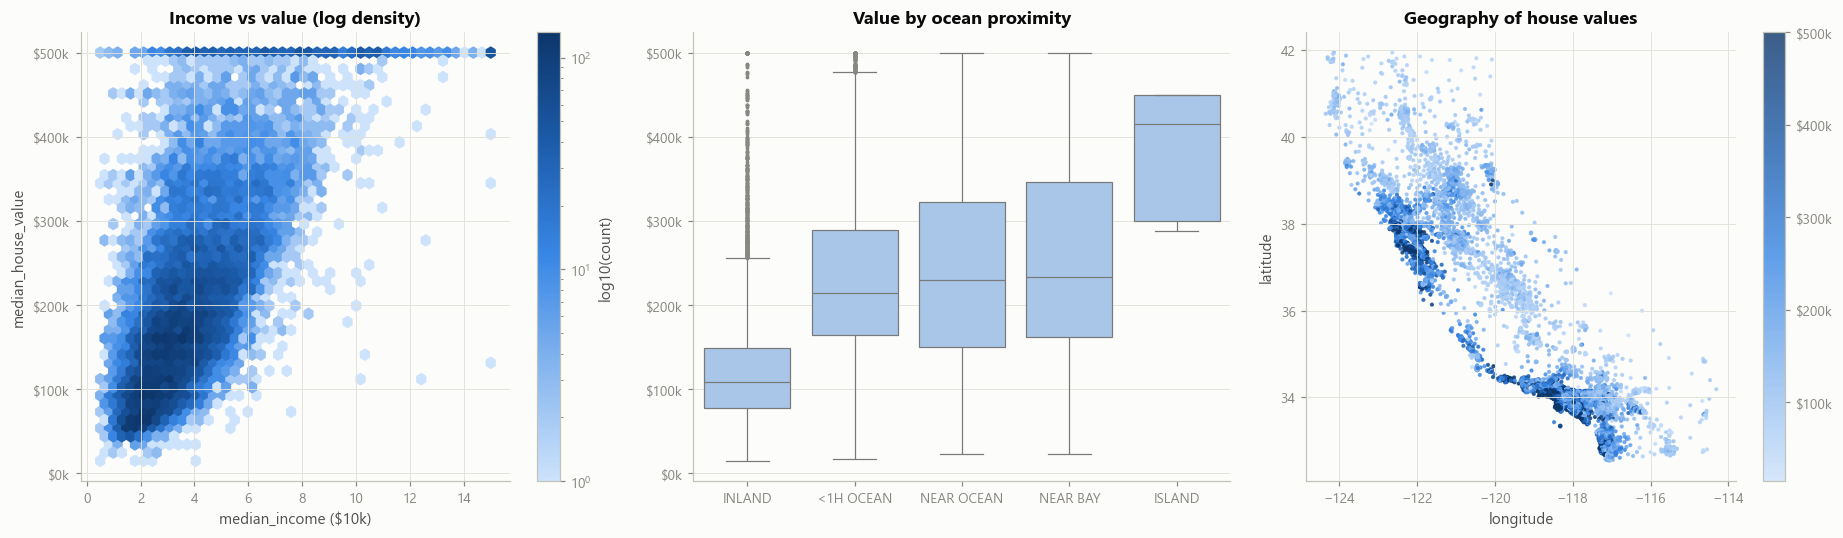

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

hb = axes[0].hexbin(data["median_income"], data[TARGET], gridsize=45, cmap=SEQ, mincnt=1, bins="log")
axes[0].yaxis.set_major_formatter(usd)
axes[0].set_xlabel("median_income ($10k)"); axes[0].set_ylabel("median_house_value")
axes[0].set_title("Income vs value (log density)")
fig.colorbar(hb, ax=axes[0], label="log10(count)")

order = data.groupby("ocean_proximity")[TARGET].median().sort_values().index
sns.boxplot(data=data, x="ocean_proximity", y=TARGET, order=order, ax=axes[1], color="#9ec5f4",
            fliersize=1.5, linewidth=0.8, flierprops={"markerfacecolor": MUTED, "markeredgecolor": MUTED})
axes[1].yaxis.set_major_formatter(usd)
axes[1].set_title("Value by ocean proximity"); axes[1].set_xlabel(""); axes[1].set_ylabel("")

sc = axes[2].scatter(data["longitude"], data["latitude"], c=data[TARGET], cmap=SEQ, s=3, alpha=0.8)
axes[2].set_title("Geography of house values"); axes[2].set_xlabel("longitude"); axes[2].set_ylabel("latitude")
cb = fig.colorbar(sc, ax=axes[2]); cb.formatter = usd; cb.update_ticks()
fig.tight_layout(); savefig(fig, "fig04_bivariate_income_ocean_map")

* Value rises with income, but the cloud widens at higher incomes (**heteroscedasticity**), and a
  hard ceiling is visible at $500k.
* `INLAND` blocks are much cheaper than every coastal category. This is a strong categorical
  effect, so dropping `ocean_proximity` (as the old version did) threw away useful signal.
* The map shows that **location matters non-linearly**: expensive clusters along the Bay Area
  and LA/San Diego coasts. A straight line in latitude/longitude cannot capture this; trees can.

## 7. Outlier identification: IQR rule vs Isolation Forest

* **IQR rule** (univariate): flag a value outside [Q1 − 1.5·IQR, Q3 + 1.5·IQR] in *any* column.
* **Isolation Forest** (multivariate): isolates points that are easy to separate in the joint
  feature space. `contamination` is set to the same overall share as IQR flags, so we compare
  *which* rows each method picks, not how many.

In [12]:
num = add_engineered_features(data)[NUMERIC].fillna(data["total_bedrooms"].median())
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
iqr_mask = (num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)
iqr_any = iqr_mask.any(axis=1)

iso = IsolationForest(contamination=float(iqr_any.mean()), random_state=42).fit(num)
iso_flag = iso.predict(num) == -1

display(iqr_mask.sum().sort_values(ascending=False).to_frame("IQR outliers").T)
summary = pd.DataFrame({
    "rows flagged": [int(iqr_any.sum()), int(iso_flag.sum()), int((iqr_any & iso_flag).sum())],
    "median value": [data.loc[iqr_any, TARGET].median(), data.loc[iso_flag, TARGET].median(),
                     data.loc[iqr_any & iso_flag, TARGET].median()],
}, index=["IQR (any column)", "Isolation Forest", "both"])
summary["Jaccard overlap"] = (iqr_any & iso_flag).sum() / (iqr_any | iso_flag).sum()
summary

,total_bedrooms,total_rooms,households,population,bedrooms_per_room,population_per_household,median_income,rooms_per_household,longitude,latitude,housing_median_age
IQR outliers,1306,1287,1220,1196,765,711,681,511,0,0,0


,rows flagged,median value,Jaccard overlap
IQR (any column),3938,"188,400.000",0.582
Isolation Forest,3938,"187,500.000",0.582
both,2899,"205,000.000",0.582


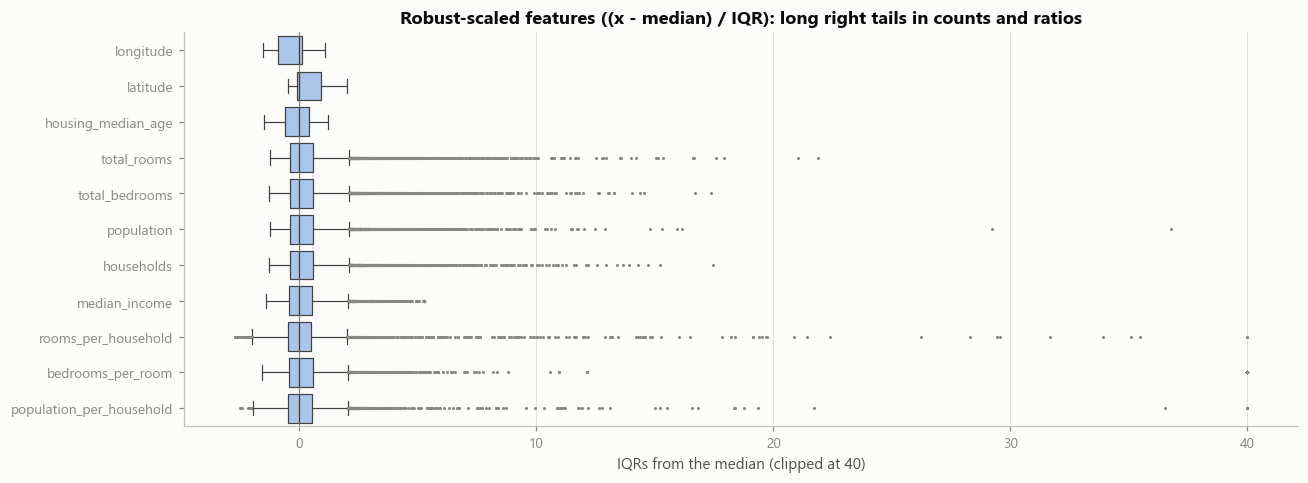

In [13]:
fig, ax = plt.subplots(figsize=(12, 4.5))
z = (num - num.median()) / iqr
sns.boxplot(data=z.clip(-15, 40), orient="h", ax=ax, color="#9ec5f4", fliersize=1, linewidth=0.8,
            flierprops={"markerfacecolor": MUTED, "markeredgecolor": MUTED})
ax.axvline(0, color=MUTED, linewidth=0.8)
ax.set_title("Robust-scaled features ((x - median) / IQR): long right tails in counts and ratios")
ax.set_xlabel("IQRs from the median (clipped at 40)")
fig.tight_layout(); savefig(fig, "fig05_outliers_boxplots")

**Comparison and decision**

* IQR flags ~19% of rows in at least one column, mostly because the count columns are naturally
  heavy-tailed. Large block groups are *real*, not errors. A univariate rule applied to 11 skewed
  columns over-flags.
* Isolation Forest (set to flag the same number of rows) agrees on most of them, with a Jaccard
  overlap of ≈ 0.58. About 1,000 rows are flagged by only one method: Isolation Forest also picks
  points that are unusual in *combination*, for example many rooms per household but few people
  (holiday homes, resorts), even when no single column is extreme.
* **Decision: keep all rows.** None of the flagged rows are data-entry errors, and removing them
  would hide exactly the cases the model must handle. We control their influence with the log
  transform (linear model) and with tree models, which are robust to extreme values. The
  censored targets are treated as a **limitation**, and §12 measures their effect.

## 8. Feature engineering and categorical encoding

Block totals depend mostly on how big the block group is, so we turn them into **per-household
ratios**. These are computed from the *raw* counts (the earlier version took logs first, which
produced meaningless "ratios of logs"):

| Feature | Formula | Meaning |
|---|---|---|
| `rooms_per_household` | total_rooms / households | average home size |
| `bedrooms_per_room` | total_bedrooms / total_rooms | layout (higher = smaller homes) |
| `population_per_household` | population / households | crowding |

`ocean_proximity` is **one-hot encoded**. For the linear model the first level (`<1H OCEAN`) is
dropped as the reference category to avoid the dummy-variable trap.

All of this happens inside `housing_features.make_pipeline`, so the Streamlit app applies exactly
the same steps.

In [14]:
eng = add_engineered_features(data)
display(eng[ENGINEERED + [TARGET]].corr()[TARGET].drop(TARGET).to_frame("r with target"))

lin_fit = make_pipeline(LinearRegression(), "linear").fit(X_train, y_train)
lin_prep = lin_fit.named_steps["prep"]
tree_prep = make_pipeline(DummyRegressor(), "tree").fit(X_train, y_train).named_steps["prep"]
print("Linear-model features:", list(lin_prep.get_feature_names_out()))
print("Tree-model features:  ", list(tree_prep.get_feature_names_out()))

,r with target
rooms_per_household,0.152
bedrooms_per_room,-0.256
population_per_household,-0.024


Linear-model features: ['total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'longitude', 'latitude', 'housing_median_age', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']
Tree-model features:   ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


## 9. Least-squares optimisation: Linear Regression from first principles

Ordinary least squares picks the coefficient vector **β** that minimises the residual sum of
squares:

$$\hat\beta = \arg\min_\beta \lVert y - X\beta \rVert^2 \quad\Rightarrow\quad X^\top X\,\hat\beta = X^\top y \;\;\text{(normal equations)}$$

We solve this ourselves in two ways, with the normal equations and with `numpy.linalg.lstsq`
(SVD-based, numerically safer), and check that we recover sklearn's `LinearRegression` exactly.

In [15]:
Xt = lin_fit[:-1].transform(X_train)          # feature engineering + imputation + log + scaling
names = list(lin_prep.get_feature_names_out())
X_design = np.column_stack([np.ones(len(Xt)), Xt])           # add intercept column
y_vec = y_train.to_numpy()

beta_normal = np.linalg.solve(X_design.T @ X_design, X_design.T @ y_vec)
beta_lstsq, *_ = np.linalg.lstsq(X_design, y_vec, rcond=None)

sk_lr = LinearRegression().fit(Xt, y_vec)
beta_sklearn = np.r_[sk_lr.intercept_, sk_lr.coef_]

print("max |normal eq − sklearn| :", np.abs(beta_normal - beta_sklearn).max())
print("max |lstsq − sklearn|     :", np.abs(beta_lstsq - beta_sklearn).max())
print("Training RSS              :", f"{np.sum((y_vec - X_design @ beta_lstsq) ** 2):.4e}")

max |normal eq − sklearn| : 1.385924406349659e-06
max |lstsq − sklearn|     : 2.561137080192566e-09
Training RSS              : 7.5313e+13


In [16]:
ols = sm.OLS(y_vec, sm.add_constant(pd.DataFrame(Xt, columns=names, index=y_train.index))).fit()
print(ols.summary(title="OLS on transformed training features (standardised; dummies vs <1H OCEAN)"))

  OLS on transformed training features (standardised; dummies vs <1H OCEAN)   
Dep. Variable:                      y   R-squared:                       0.659
Model:                            OLS   Adj. R-squared:                  0.659
Method:                 Least Squares   F-statistic:                     2128.
Date:                Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:59:37   Log-Likelihood:            -2.0705e+05
No. Observations:               16512   AIC:                         4.141e+05
Df Residuals:                   16496   BIC:                         4.143e+05
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
const               

In [17]:
num_cols = [n for n in names if not n.startswith("ocean_proximity")]
Xv = sm.add_constant(pd.DataFrame(Xt, columns=names)[num_cols])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                index=num_cols, name="VIF").sort_values(ascending=False)
vif.to_frame()

,VIF
total_rooms,"4,535.882"
households,"4,383.391"
population,771.066
rooms_per_household,539.824
population_per_household,104.142
total_bedrooms,84.338
bedrooms_per_room,14.071
latitude,10.156
longitude,9.625
median_income,2.733


**Interpretation**

* The hand-solved β matches sklearn to floating-point precision. `LinearRegression` *is* the
  least-squares solution.
* Almost every coefficient is statistically significant (p < 0.05), largely because n ≈ 16,500.
  Significance here does **not** mean the linear form is correct (see the residuals in §12).
* **VIF ≫ 10** for the log counts (`total_rooms`, `households` ≈ 4,500) and for the ratios built
  from them confirms severe **multicollinearity**. The ratios are exact functions of the logged
  counts (log(a/b) = log a − log b). The symptoms are huge opposite-signed coefficients
  (`households` +$537k, `total_rooms` −$144k) and `bedrooms_per_room` turning *positive* even
  though its raw correlation with price is negative. These coefficients cannot be read one by one.
  Predictions are unaffected, so interpretation should rely on income, location and age, whose
  VIFs are low.
* A Jarque–Bera test far from normal and a large condition number show that the OLS assumptions
  (normal, constant-variance errors) are violated. This motivates the non-linear models.

## 10. Regression models and hyper-parameter tuning

| Model | Why it is included | Hardware |
|---|---|---|
| Baseline (predict the mean) | floor that every model must beat | CPU |
| Linear Regression | interpretable least-squares reference | CPU |
| Linear Regression, log target | tests whether modelling `log(price)` fixes skew and heteroscedasticity | CPU |
| Random Forest | bagged trees, non-linear, robust | CPU (all cores) |
| XGBoost | gradient-boosted trees | **GPU (RTX 3050, CUDA)** |

The tree models are tuned with `RandomizedSearchCV` (5-fold, RMSE) on the training set only.

In [18]:
rf_search = RandomizedSearchCV(
    make_pipeline(RandomForestRegressor(random_state=42, n_jobs=1), "tree"),
    {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [None, 20, 30],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [0.33, 0.5, "sqrt", 1.0],
    },
    n_iter=20, cv=cv5, scoring="neg_root_mean_squared_error", n_jobs=-1, random_state=42,
)
t0 = time.perf_counter()
rf_search.fit(X_train, y_train)
rf_time = time.perf_counter() - t0
print(f"Random Forest search: 100 fits on CPU in {rf_time:.0f}s")
print("Best params:", rf_search.best_params_, f"| CV RMSE {-rf_search.best_score_:,.0f}")

Random Forest search: 100 fits on CPU in 297s
Best params: {'model__n_estimators': 500, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': 30} | CV RMSE 49,153


In [19]:
xgb_search = RandomizedSearchCV(
    make_pipeline(XGBRegressor(device=DEVICE, tree_method="hist", random_state=42), "tree"),
    {
        "model__n_estimators": [400, 800, 1200],
        "model__max_depth": [4, 6, 8],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.6, 0.8, 1.0],
        "model__min_child_weight": [1, 3, 5],
        "model__reg_lambda": [1, 5],
    },
    n_iter=30, cv=cv5, scoring="neg_root_mean_squared_error",
    n_jobs=1,                      # one fit at a time: the GPU does the parallel work
    random_state=42,
)
t0 = time.perf_counter()
xgb_search.fit(X_train, y_train)
xgb_time = time.perf_counter() - t0
print(f"XGBoost search: 150 fits on {DEVICE.upper()} in {xgb_time:.0f}s")
print("Best params:", xgb_search.best_params_, f"| CV RMSE {-xgb_search.best_score_:,.0f}")

XGBoost search: 150 fits on CUDA in 319s
Best params: {'model__subsample': 0.7, 'model__reg_lambda': 5, 'model__n_estimators': 1200, 'model__min_child_weight': 1, 'model__max_depth': 8, 'model__learning_rate': 0.03, 'model__colsample_bytree': 0.6} | CV RMSE 45,053


In [20]:
# How much does the GPU actually help? Time one fit of the best XGBoost configuration on each device.
bench = {}
for dev in (["cuda", "cpu"] if DEVICE == "cuda" else ["cpu"]):
    p = xgb_search.best_estimator_.named_steps["model"].get_params()
    p.update(device=dev, n_jobs=-1 if dev == "cpu" else None)
    pipe = make_pipeline(XGBRegressor(**p), "tree")
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); bench[dev] = time.perf_counter() - t0
print({k: f"{v:.2f}s" for k, v in bench.items()})

{'cuda': '5.82s', 'cpu': '3.64s'}


**GPU vs CPU, honestly.** For this dataset (~16,500 rows × 16 features) one GPU fit is *not*
faster than a multi-core CPU fit. Copying the data to the GPU and launching kernels costs more
than the GPU saves on such a small matrix (see the timings above; they vary a little between
runs). The GPU still kept the search practical: XGBoost ran one fit at a time on the GPU, 150
fits in roughly 5 minutes, without competing for CPU cores. GPU training pays off clearly with
hundreds of thousands of rows or more. Running XGBoost on the CPU with parallel search workers
would be a reasonable choice for data of this size.

## 11. Validation and method comparison

### 11a. 5-fold cross-validation on the training set (mean ± std)
All models use **the same folds**, so their fold scores can be compared pair by pair.

In [21]:
models = {
    "Baseline (mean)": make_pipeline(DummyRegressor(strategy="mean"), "tree"),
    "Linear Regression": make_pipeline(LinearRegression(), "linear"),
    "Linear Regression (log target)": make_pipeline(
        TransformedTargetRegressor(regressor=LinearRegression(), func=np.log, inverse_func=np.exp), "linear"),
    "Random Forest": rf_search.best_estimator_.set_params(model__n_jobs=-1),
    "XGBoost": xgb_search.best_estimator_,
}

cv_raw, cv_rows = {}, []
for name, m in models.items():
    r = cross_validate(m, X_train, y_train, cv=cv5, scoring=SCORING, n_jobs=1)
    cv_raw[name] = r
    cv_rows.append({"model": name,
                    "MAE mean": -r["test_MAE"].mean(), "MAE std": r["test_MAE"].std(),
                    "RMSE mean": -r["test_RMSE"].mean(), "RMSE std": r["test_RMSE"].std(),
                    "R2 mean": r["test_R2"].mean(), "R2 std": r["test_R2"].std()})
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table

,MAE mean,MAE std,RMSE mean,RMSE std,R2 mean,R2 std
model,,,,,,
Baseline (mean),"91,301.789",917.145,"115,698.630","1,068.186",-0.000,0.000
Linear Regression,"50,601.297",390.241,"67,830.553",742.190,0.656,0.004
Linear Regression (log target),"44,624.544",735.313,"66,027.266",971.593,0.674,0.012
Random Forest,"32,282.804",331.769,"49,153.366",876.604,0.819,0.006
XGBoost,"29,237.966",346.557,"45,053.270",963.939,0.848,0.007


In [22]:
# Paired t-test on the 5 fold RMSEs of the two best models (same folds -> paired samples)
rf_f, xgb_f = -cv_raw["Random Forest"]["test_RMSE"], -cv_raw["XGBoost"]["test_RMSE"]
t, p = stats.ttest_rel(rf_f, xgb_f)
print("RF fold RMSE :", np.round(rf_f, 0))
print("XGB fold RMSE:", np.round(xgb_f, 0))
print(f"Paired t-test RF vs XGB: t = {t:.2f}, p = {p:.4f}")

RF fold RMSE : [48458. 49395. 49222. 50615. 48077.]
XGB fold RMSE: [44539. 45891. 44794. 46365. 43677.]
Paired t-test RF vs XGB: t = 23.52, p = 0.0000


### 11b. Final evaluation on the held-out test set
Each model is refit on the full training set and scored **once** on the untouched 20% test set.

In [23]:
fitted, test_pred, test_rows = {}, {}, []
for name, m in models.items():
    fitted[name] = m.fit(X_train, y_train)
    test_pred[name] = fitted[name].predict(X_test)
    tr = metrics(y_train, fitted[name].predict(X_train))
    te = metrics(y_test, test_pred[name])
    test_rows.append({"model": name, "test MAE": te["MAE"], "test RMSE": te["RMSE"], "test R2": te["R2"],
                      "train R2": tr["R2"], "overfit gap (train-test R2)": tr["R2"] - te["R2"]})
test_table = pd.DataFrame(test_rows).set_index("model")
BEST = cv_table.drop(index=["Baseline (mean)"])["RMSE mean"].idxmin()
print("Best model by CV RMSE:", BEST)
test_table

Best model by CV RMSE: XGBoost


,test MAE,test RMSE,test R2,train R2,overfit gap (train-test R2)
model,,,,,
Baseline (mean),"90,806.788","114,165.270",-0.000,0.000,0.000
Linear Regression,"50,542.375","67,806.756",0.647,0.659,0.012
Linear Regression (log target),"44,973.623","79,670.119",0.513,0.678,0.165
Random Forest,"31,111.418","46,826.164",0.832,0.976,0.144
XGBoost,"28,219.193","42,735.565",0.860,0.983,0.123


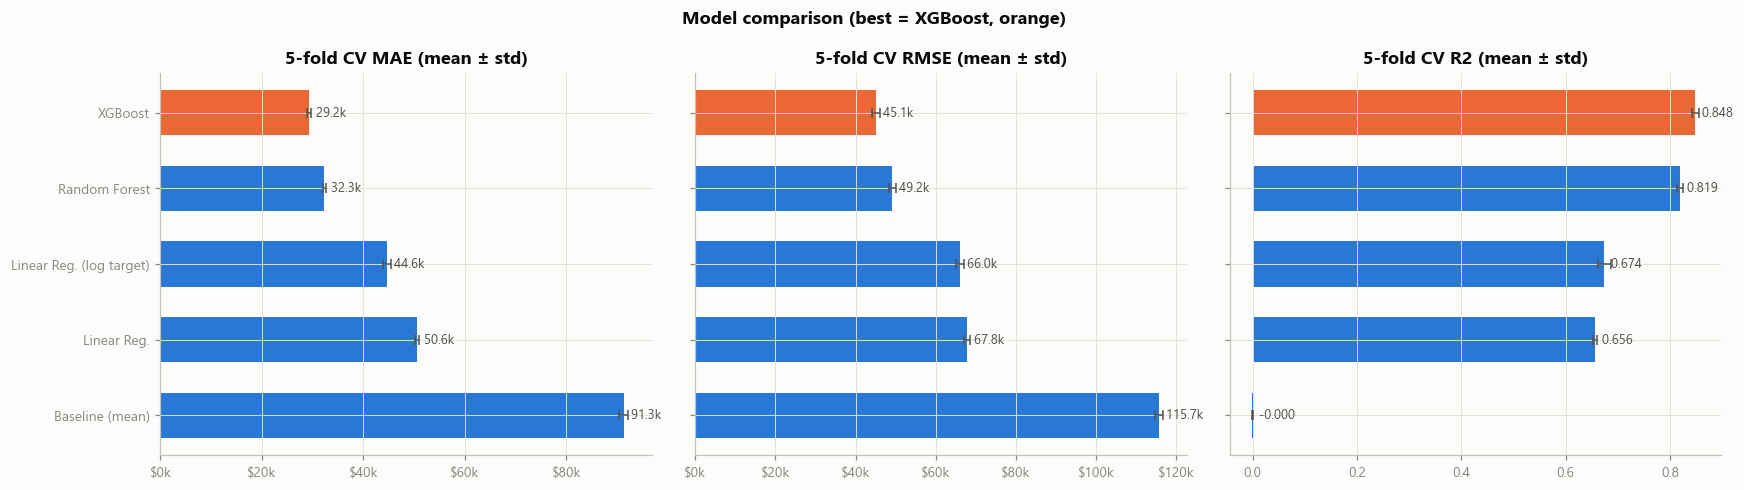

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
order = cv_table.sort_values("RMSE mean", ascending=False).index
short = {n: n.replace("Linear Regression", "Linear Reg.") for n in order}
for ax, met, fmt in zip(axes, ["MAE", "RMSE", "R2"], [usd, usd, None]):
    vals, errs = cv_table.loc[order, f"{met} mean"], cv_table.loc[order, f"{met} std"]
    colors = [ORANGE if n == BEST else BLUE for n in order]
    ax.barh([short[n] for n in order], vals, xerr=errs, color=colors, height=0.6,
            error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 3})
    ax.set_title(f"5-fold CV {met} (mean ± std)")
    if fmt: ax.xaxis.set_major_formatter(fmt)
    for i, v in enumerate(vals):
        ax.text(v, i, f"  {v/1000:,.1f}k" if fmt else f"  {v:.3f}", va="center", fontsize=8.5, color=INK2)
    if ax is not axes[0]: ax.set_yticklabels([])
fig.suptitle(f"Model comparison (best = {BEST}, orange)", fontweight="bold", color=INK)
fig.tight_layout(); savefig(fig, "fig06_model_comparison_cv")

### 11c. Spatial validation: does random K-fold flatter the trees?

Neighbouring block groups are very similar. With a random split, a test block almost always has
a near-identical neighbour in training, so the score partly measures *interpolation*. With
**GroupKFold on 0.5° grid cells**, whole areas are held out together, which better simulates
predicting a region the model has not seen.

In [25]:
groups = (np.floor(X_train["latitude"] / 0.5) * 1000 + np.floor(X_train["longitude"] / 0.5)).astype(int)
gkf = GroupKFold(n_splits=5)
spatial_rows = []
for name in ["Linear Regression", "Random Forest", "XGBoost"]:
    r = cross_validate(models[name], X_train, y_train, cv=gkf, groups=groups, scoring=SCORING, n_jobs=1)
    spatial_rows.append({"model": name,
                         "random KFold RMSE": cv_table.loc[name, "RMSE mean"],
                         "spatial GroupKFold RMSE": -r["test_RMSE"].mean(),
                         "random KFold R2": cv_table.loc[name, "R2 mean"],
                         "spatial GroupKFold R2": r["test_R2"].mean()})
spatial_table = pd.DataFrame(spatial_rows).set_index("model")
spatial_table["RMSE increase %"] = (spatial_table["spatial GroupKFold RMSE"] / spatial_table["random KFold RMSE"] - 1) * 100
print(f"{groups.nunique()} spatial groups")
spatial_table

169 spatial groups


,random KFold RMSE,spatial GroupKFold RMSE,random KFold R2,spatial GroupKFold R2,RMSE increase %
model,,,,,
Linear Regression,"67,830.553","70,044.025",0.656,0.604,3.263
Random Forest,"49,153.366","59,340.489",0.819,0.716,20.725
XGBoost,"45,053.270","59,995.140",0.848,0.710,33.165


**Why the trees beat Linear Regression, with evidence**

1. **Non-linearity.** Value saturates and curves with income, and the location effect is a
   patchwork of coastal clusters (fig04). A straight line in latitude/longitude cannot represent
   this; trees split the map into regions.
2. **Interactions.** The same income buys far less house inland than on the coast. Trees model
   income × location interactions automatically; OLS would need hand-made interaction terms.
3. **Skew and heteroscedasticity.** Modelling log(price) lowers the linear model's MAE (≈ $50.5k →
   $45.0k), but its test RMSE gets *worse*. Back-transforming with exp() blows up a few extreme
   predictions, and RMSE punishes those heavily. It still trails the trees by a wide margin, so
   the problem is the *functional form*, not only the target scale.
4. **Overfitting check.** The trees fit the training data almost perfectly (train R² 0.98). Their
   train–test gaps are 0.14 (RF) and 0.12 (XGBoost), yet their *test* errors are still far below
   Linear Regression's, so the extra variance is worth paying for. Linear Regression barely
   overfits (gap 0.01); it **underfits**.
5. **RF vs XGBoost.** XGBoost wins on all 5 folds. The paired t-test on fold RMSEs gives
   p < 0.001, though with only 5 overlapping folds the test is indicative rather than exact.
6. **Spatial validation.** When whole 0.5° regions are held out, both trees lose ~20–33% accuracy
   (R² ≈ 0.71), while Linear Regression loses only 3%. Part of the trees' advantage is local
   interpolation from neighbouring blocks, and XGBoost's lead over RF disappears for unseen
   regions. The random-KFold scores are therefore optimistic for genuinely new areas, though the
   trees remain clearly better than Linear Regression.

## 12. Residual analysis

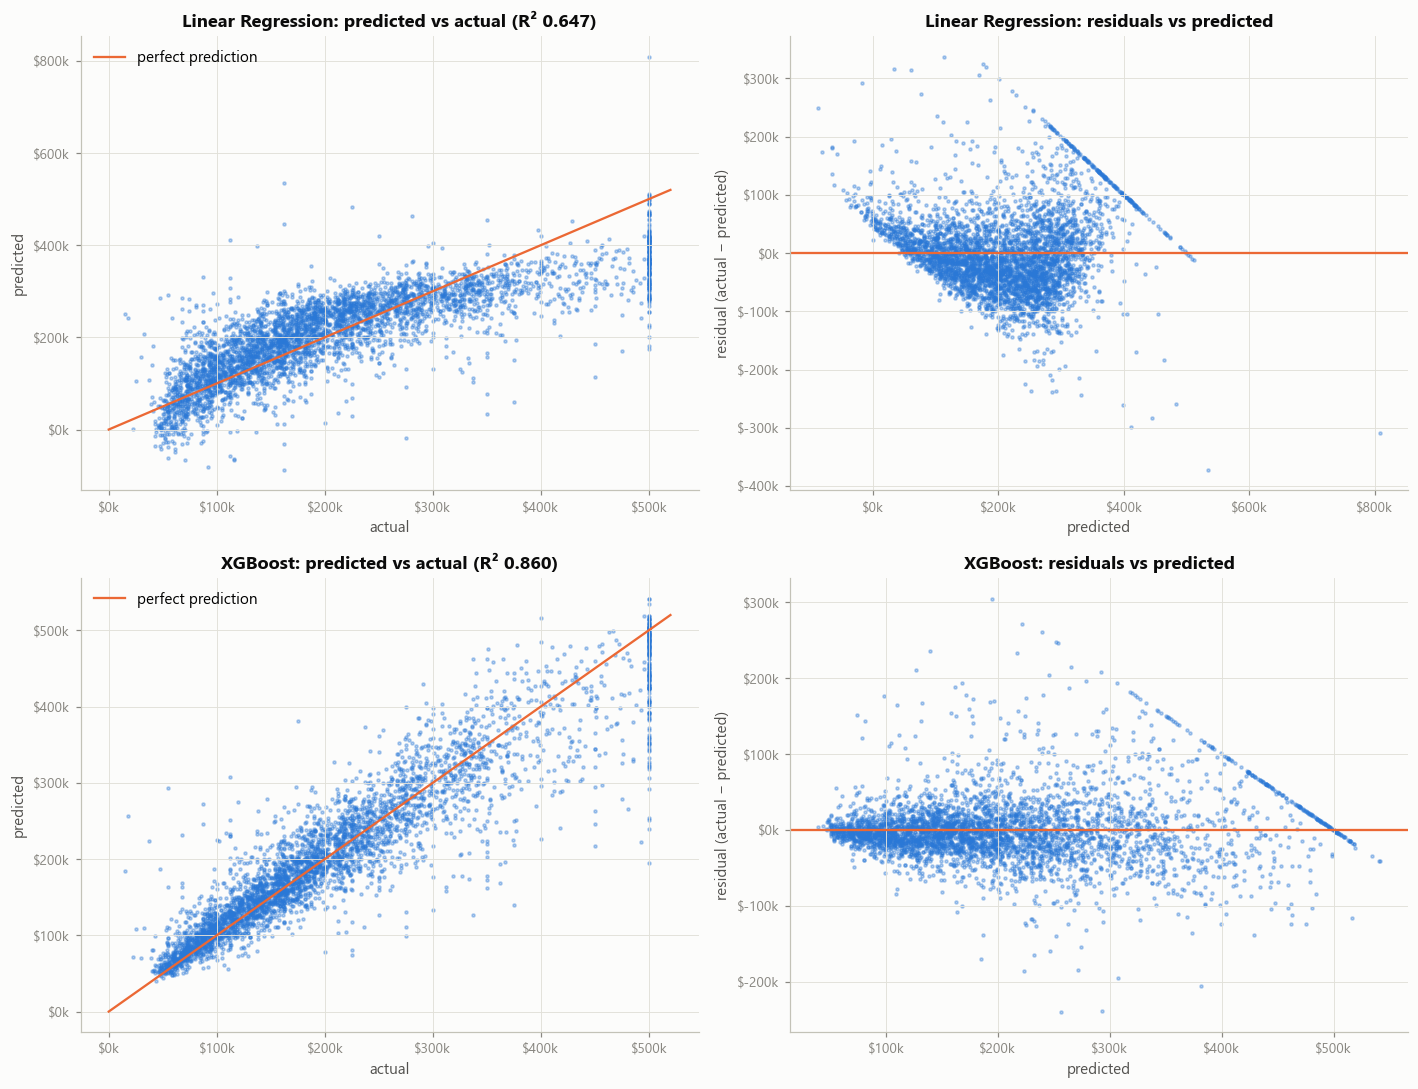

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, name in enumerate(["Linear Regression", BEST]):
    pred = test_pred[name]; resid = y_test - pred
    ax = axes[row, 0]
    ax.scatter(y_test, pred, s=4, alpha=0.35, color=BLUE)
    ax.plot([0, 520000], [0, 520000], color=ORANGE, linewidth=1.5, label="perfect prediction")
    ax.set_title(f"{name}: predicted vs actual (R² {r2_score(y_test, pred):.3f})")
    ax.set_xlabel("actual"); ax.set_ylabel("predicted")
    ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(usd); ax.legend(loc="upper left")

    ax = axes[row, 1]
    ax.scatter(pred, resid, s=4, alpha=0.35, color=BLUE)
    ax.axhline(0, color=ORANGE, linewidth=1.5)
    ax.set_title(f"{name}: residuals vs predicted")
    ax.set_xlabel("predicted"); ax.set_ylabel("residual (actual − predicted)")
    ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(usd)
fig.tight_layout(); savefig(fig, "fig07_residuals_pred_vs_actual")

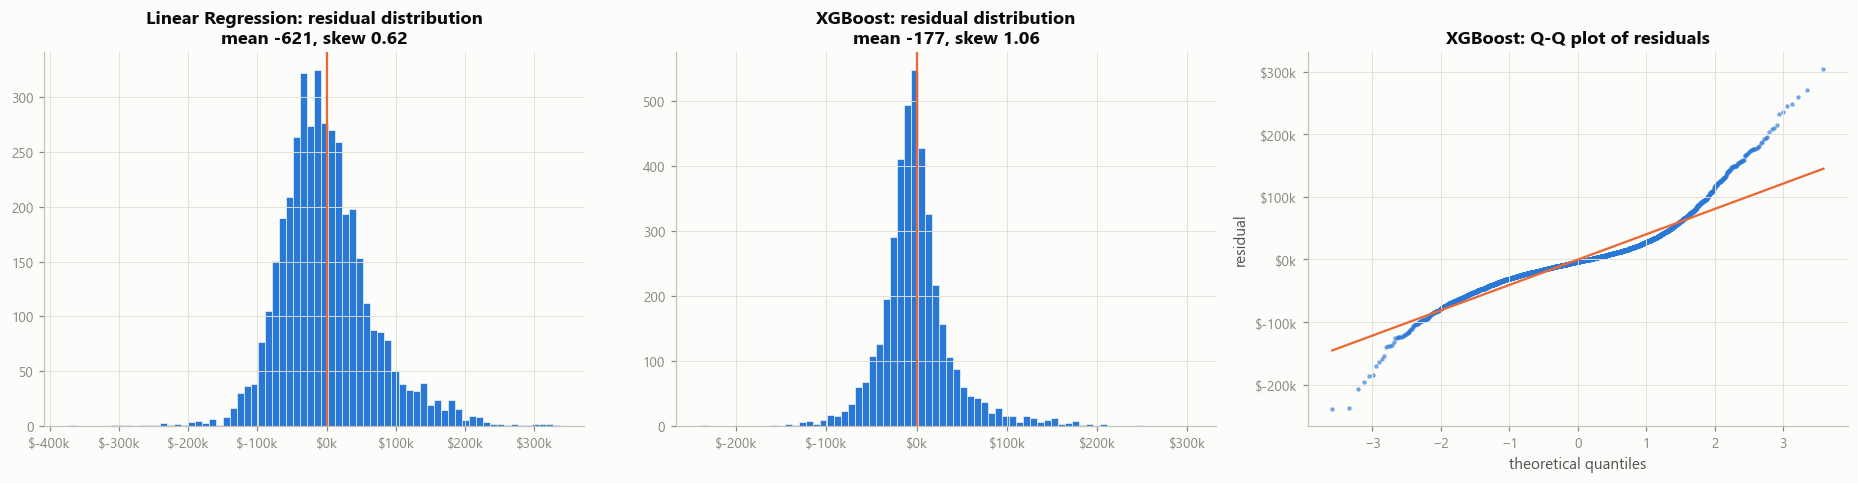

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, name in zip(axes[:2], ["Linear Regression", BEST]):
    resid = y_test - test_pred[name]
    ax.hist(resid, bins=70, color=BLUE, edgecolor="#fcfcfb", linewidth=0.4)
    ax.axvline(0, color=ORANGE, linewidth=1.5)
    ax.set_title(f"{name}: residual distribution\nmean {resid.mean():,.0f}, skew {stats.skew(resid):.2f}")
    ax.xaxis.set_major_formatter(usd)
(osm, osr), (slope, intercept, _) = stats.probplot(y_test - test_pred[BEST], dist="norm")
axes[2].scatter(osm, osr, s=4, color=BLUE, alpha=0.5)
axes[2].plot(osm, slope * osm + intercept, color=ORANGE, linewidth=1.5)
axes[2].set_title(f"{BEST}: Q-Q plot of residuals"); axes[2].set_xlabel("theoretical quantiles")
axes[2].set_ylabel("residual"); axes[2].yaxis.set_major_formatter(usd)
fig.tight_layout(); savefig(fig, "fig08_residual_distribution_qq")

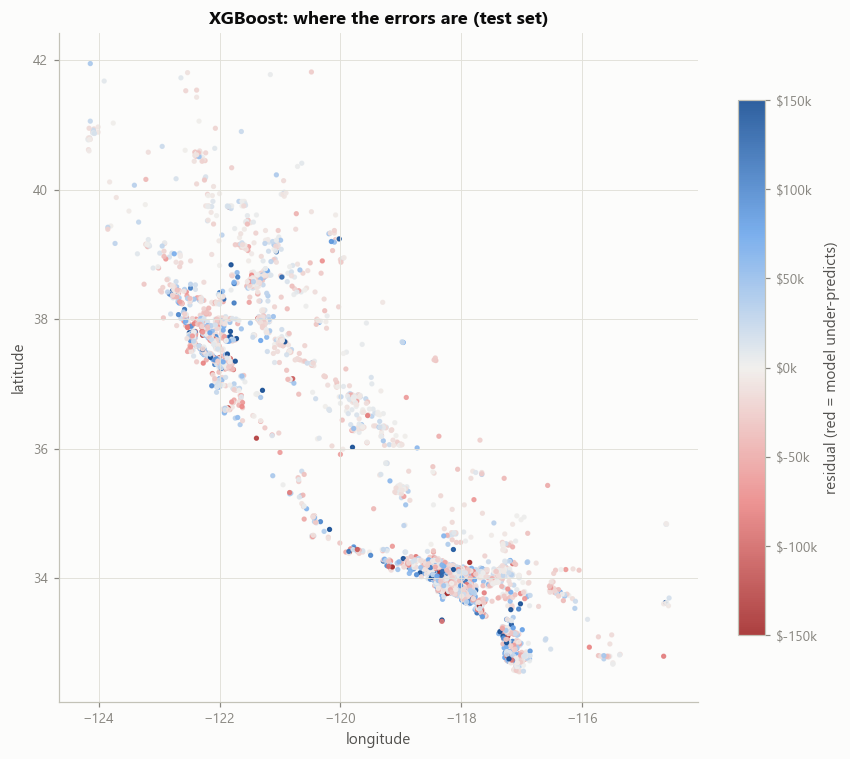

In [28]:
resid_best = y_test - test_pred[BEST]
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(X_test["longitude"], X_test["latitude"], c=resid_best.clip(-150000, 150000),
                cmap=DIV.reversed(), vmin=-150000, vmax=150000, s=6, alpha=0.9)
cb = fig.colorbar(sc, ax=ax, shrink=0.8); cb.formatter = usd; cb.update_ticks()
cb.set_label("residual (red = model under-predicts)")
ax.set_title(f"{BEST}: where the errors are (test set)")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
fig.tight_layout(); savefig(fig, "fig09_residual_map")

In [29]:
capped = y_test >= 500001
rows = []
for name in ["Linear Regression", BEST]:
    for label, mask in [("uncapped targets", ~capped), ("capped at $500,001", capped)]:
        m = metrics(y_test[mask], test_pred[name][mask])
        rows.append({"model": name, "subset": label, "rows": int(mask.sum()), "MAE": m["MAE"], "RMSE": m["RMSE"],
                     "mean residual": float((y_test[mask] - test_pred[name][mask]).mean())})
for name in ["Linear Regression", BEST]:
    print(f"{name}: {(test_pred[name] < 0).sum()} negative price predictions, "
          f"{(test_pred[name] > 500001).sum()} above the $500,001 cap")
pd.DataFrame(rows).set_index(["model", "subset"])

Linear Regression: 54 negative price predictions, 6 above the $500,001 cap
XGBoost: 0 negative price predictions, 34 above the $500,001 cap


rows         MAE        RMSE  \
model             subset                                             
Linear Regression uncapped targets    3949  46,883.853  61,961.493   
                  capped at $500,001   179 131,254.695 146,054.856   
XGBoost           uncapped targets    3949  26,825.179  39,910.240   
                  capped at $500,001   179  58,973.172  83,532.664   

                                      mean residual  
model             subset                             
Linear Regression uncapped targets       -6,427.505  
                  capped at $500,001    127,484.660  
XGBoost           uncapped targets       -2,684.271  
                  capped at $500,001     55,127.314

**Residual findings**

* **Linear Regression:** the residuals-vs-predicted plot shows a **funnel** (variance grows with
  price) and a curve, which are the classic signs of heteroscedasticity and a wrong functional
  form. It predicts **negative prices** for 54 test blocks, which is impossible and shows that a
  straight line extrapolates badly. XGBoost never does this.
* **Best tree model:** residuals are centred near zero with no strong trend. The Q-Q plot has
  heavy tails, so large errors happen more often than a normal distribution would suggest.
* **The cap line:** both models show a diagonal band of residuals for blocks at $500,001. Their
  true value is *at least* that amount. On the 179 capped test blocks, XGBoost's MAE more than
  doubles (≈ $59k vs $27k) and it under-predicts by ≈ $55k on average. Errors there are
  partly *unknowable*: the true value could be far above $500k.
* **Spatial pattern:** the largest errors cluster in the expensive coastal Bay Area and LA, where
  prices vary block by block and many targets are capped. Errors in inland areas are small.

## 13. Interpretation of important predictors

Three complementary views:
1. **Standardised OLS coefficients:** the direction and size of each linear effect.
2. **Built-in tree importances:** how much each feature reduces error inside the trees.
3. **Grouped permutation importance on the test set:** how much the test RMSE rises when one
   *model feature* is shuffled. Shuffling happens *after* feature engineering, so shuffling
   `total_rooms` does not also break the ratios built from it, and all one-hot `ocean_proximity`
   columns are shuffled together as one feature. It is model-agnostic, so the three models can be
   compared directly.

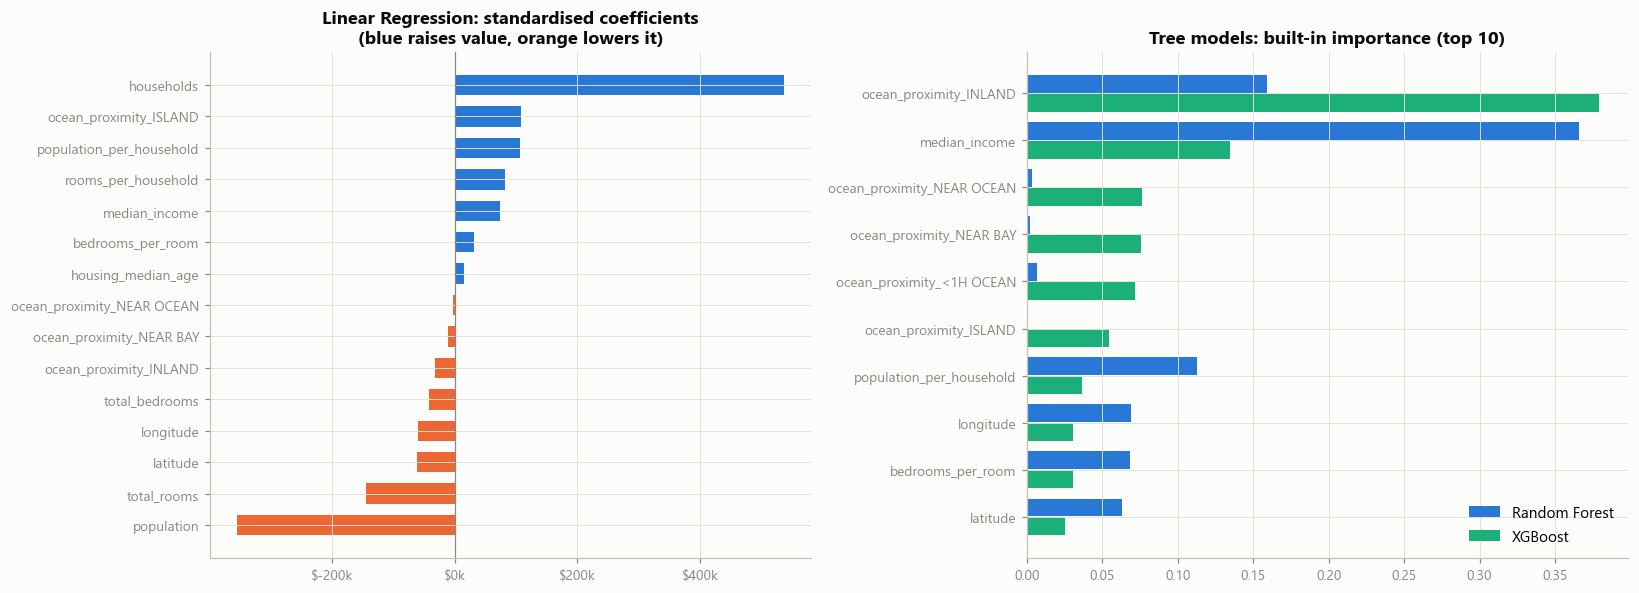

,Random Forest,XGBoost
ocean_proximity_INLAND,0.159,0.379
median_income,0.366,0.135
ocean_proximity_NEAR OCEAN,0.003,0.076
ocean_proximity_NEAR BAY,0.002,0.076
ocean_proximity_<1H OCEAN,0.007,0.072
ocean_proximity_ISLAND,0.000,0.054
population_per_household,0.113,0.036
longitude,0.069,0.031
bedrooms_per_room,0.069,0.030
latitude,0.063,0.026


In [30]:
lr_fit = fitted["Linear Regression"]
coef = pd.Series(lr_fit.named_steps["model"].coef_, index=lr_fit.named_steps["prep"].get_feature_names_out()).sort_values()
tree_names = fitted[BEST].named_steps["prep"].get_feature_names_out()
builtin = pd.DataFrame({
    "Random Forest": fitted["Random Forest"].named_steps["model"].feature_importances_,
    "XGBoost": fitted["XGBoost"].named_steps["model"].feature_importances_,
}, index=tree_names).sort_values(BEST, ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(coef.index, coef.values, color=[ORANGE if v < 0 else BLUE for v in coef.values], height=0.65)
axes[0].axvline(0, color=MUTED, linewidth=0.8)
axes[0].xaxis.set_major_formatter(usd)
axes[0].set_title("Linear Regression: standardised coefficients\n(blue raises value, orange lowers it)")
top = builtin.head(10)[::-1]
y = np.arange(len(top))
axes[1].barh(y + 0.2, top["Random Forest"], height=0.38, color=BLUE, label="Random Forest")
axes[1].barh(y - 0.2, top["XGBoost"], height=0.38, color=AQUA, label="XGBoost")
axes[1].set_yticks(y, top.index); axes[1].legend(loc="lower right")
axes[1].set_title("Tree models: built-in importance (top 10)")
fig.tight_layout(); savefig(fig, "fig10_coefficients_builtin_importance")
builtin.round(3)

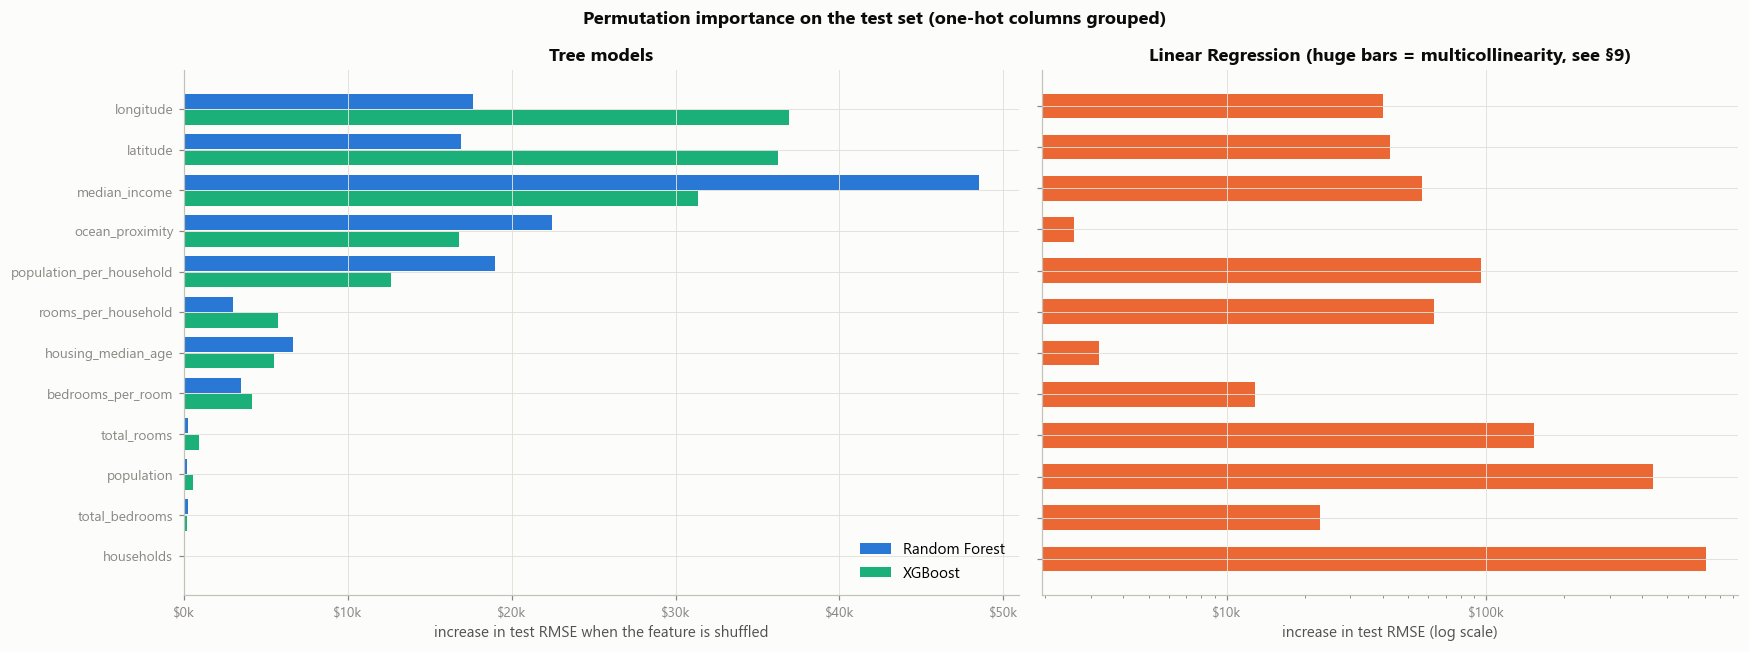

,Linear Regression,Random Forest,XGBoost
longitude,"40,230.659","17,637.082","36,946.716"
latitude,"42,578.664","16,887.436","36,232.419"
median_income,"56,439.030","48,523.341","31,371.894"
ocean_proximity,"2,582.292","22,471.414","16,755.712"
population_per_household,"95,367.409","19,002.515","12,625.017"
rooms_per_household,"63,076.566","2,981.431","5,711.472"
housing_median_age,"3,219.247","6,637.055","5,474.406"
bedrooms_per_room,"12,876.074","3,490.100","4,130.862"
total_rooms,"153,076.104",247.404,941.016
population,"440,784.968",158.522,547.190


In [31]:
def grouped_permutation_importance(pipe, X, y, n_repeats=5, seed=42):
    # Shuffle each model feature (one-hot columns as one group) after preprocessing; return RMSE increase.
    Xt = pipe[:-1].transform(X)
    names = pipe.named_steps["prep"].get_feature_names_out()
    model = pipe.named_steps["model"]
    base = np.sqrt(mean_squared_error(y, model.predict(Xt)))
    groups = {}
    for i, n in enumerate(names):
        groups.setdefault("ocean_proximity" if n.startswith("ocean_proximity") else n, []).append(i)
    rng = np.random.default_rng(seed)
    out = {}
    for g, idx in groups.items():
        deltas = []
        for _ in range(n_repeats):
            Xp = Xt.copy()
            Xp[:, idx] = Xt[rng.permutation(len(Xt))][:, idx]
            deltas.append(np.sqrt(mean_squared_error(y, model.predict(Xp))) - base)
        out[g] = np.mean(deltas)
    return pd.Series(out)

perm = pd.DataFrame({name: grouped_permutation_importance(fitted[name], X_test, y_test)
                     for name in ["Linear Regression", "Random Forest", "XGBoost"]}).sort_values(BEST)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]})
y = np.arange(len(perm)); h = 0.4
axes[0].barh(y + h / 2, perm["Random Forest"], height=h - 0.03, color=BLUE, label="Random Forest")
axes[0].barh(y - h / 2, perm["XGBoost"], height=h - 0.03, color=AQUA, label="XGBoost")
axes[0].set_yticks(y, perm.index); axes[0].xaxis.set_major_formatter(usd)
axes[0].set_xlabel("increase in test RMSE when the feature is shuffled")
axes[0].set_title("Tree models"); axes[0].legend(loc="lower right")

lr_perm = perm["Linear Regression"]
axes[1].barh(y, lr_perm, height=0.6, color=ORANGE)
axes[1].set_xscale("log"); axes[1].set_yticks(y, [])
axes[1].xaxis.set_major_formatter(usd)
axes[1].set_xlabel("increase in test RMSE (log scale)")
axes[1].set_title("Linear Regression (huge bars = multicollinearity, see §9)")
fig.suptitle("Permutation importance on the test set (one-hot columns grouped)", fontweight="bold", color=INK)
fig.tight_layout(); savefig(fig, "fig11_permutation_importance")
perm.sort_values(BEST, ascending=False)

**What drives house value**

* **Income and location dominate.** For the tree models the top features are `median_income`,
  `latitude`/`longitude` and `ocean_proximity`. Random Forest ranks income first (+$48k RMSE when
  shuffled). XGBoost spreads the credit more evenly between longitude, latitude (+$37k each) and
  income (+$31k): it uses fine-grained location to capture neighbourhood price levels, which
  overlap with income.
* **`ocean_proximity` matters for the trees** (+$17–22k). Its gain-based importance is even
  higher: `INLAND` is XGBoost's single top split feature. In OLS, `INLAND` blocks are about −$31k
  versus `<1H OCEAN`, holding the other features fixed.
* **Crowding** (`population_per_household`) is the strongest engineered feature (+$13–19k).
  Larger homes and room layout (`rooms_per_household`, `bedrooms_per_room`) add a little, and
  `housing_median_age` adds a little.
* **Raw totals are nearly useless to the trees** (< $1k). Once per-household ratios exist, block
  size carries no extra price signal, which justifies the feature engineering.
* **Linear Regression's huge bars are a warning, not insight.** Shuffling `households` raises its
  RMSE by about $700k. The model balances the collinear log counts with large opposite-signed
  coefficients (VIF ≈ 4,500, §9), and shuffling one breaks that balance. Its meaningful drivers
  are income (+$56k) and latitude/longitude (+$40k each).
* Gain-based and permutation importances disagree in places. Gain measures how often a feature
  is used for splits; permutation measures how much accuracy depends on it. Permutation is the
  more reliable of the two for interpretation.

## 14. Error of the chained Streamlit app

In the app, the user clicks a map location. `median_income` and `ocean_proximity` are then
**guessed from latitude/longitude** by the helper models, instead of being measured. Here we
replace those two true columns in the test set with the helpers' guesses and re-score the best
model. This is the honest accuracy of the app.

In [32]:
ocean_model = joblib.load(MODELS / "ocean_model.joblib")
income_model = joblib.load(MODELS / "income_model.joblib")
LOC = ["latitude", "longitude"]

X_chain = X_test.copy()
X_chain["median_income"] = income_model.predict(X_test[LOC])
X_chain["ocean_proximity"] = ocean_model.predict(X_test[LOC])
chain = metrics(y_test, fitted[BEST].predict(X_chain))
direct = metrics(y_test, test_pred[BEST])
chain_table = pd.DataFrame([direct, chain], index=["true inputs (notebook)", "helper-predicted inputs (app)"])
chain_table

,MAE,RMSE,R2
true inputs (notebook),"28,219.193","42,735.565",0.860
helper-predicted inputs (app),"31,410.050","47,516.198",0.827


Using guessed inputs costs less than one might expect: R² falls from about 0.86 to 0.83 and MAE
rises by about $3k, even though the income helper explains only ~56% of income's variance. The
reason is that the price model already sees latitude/longitude, so the *location-driven* part of
income is largely redundant. What is lost is the block-to-block income variation that location
cannot explain.

This test still flatters the app. It keeps the true room, age and population figures for each
block, while real app users supply rough guesses and neighbourhood presets. **The app should be
presented as an illustrative estimate, not a valuation.**

## 15. Limitations and ethical issues

### Limitations
* **Old data:** 1990 prices are not today's prices (California values have risen several times
  over since). The model learns *relative* patterns, not current values.
* **Aggregation:** each row is a block-group median, not a house. Predicting one specific home
  from it is an ecological inference and ignores condition, size and features.
* **Censoring:** 4.7% of targets (and ages, and incomes) are capped. Errors above $500k are
  unknowable and biased downwards.
* **Spatial dependence:** random K-fold overstates accuracy for unseen regions (§11c).
* **Chained inputs:** the app guesses income from location, which degrades accuracy (§14).
* **Missing variables:** no school quality, crime, transport or house-level attributes.

### Ethical issues in location and property data
* **Proxy discrimination / digital redlining:** location and income are strongly correlated with
  race and ethnicity because of historical segregation. A model that prices by location can
  reproduce past discrimination in lending, insurance or rents, even with no protected
  attribute in the data.
* **Feedback loops:** if automated valuations drive real prices or lending decisions,
  under-valued neighbourhoods get less credit, which keeps values low and is then "confirmed"
  by the next model.
* **Privacy:** fine-grained location plus income can re-identify people in small areas. Census
  data is aggregated to block groups for exactly this reason. Joining it with other data sources
  can undo that protection.
* **Transparency and accountability:** people affected by an automated valuation should be able
  to see the main drivers (§13) and contest the result.
* **Appropriate use:** suitable for teaching and exploratory market analysis. **Not suitable** for
  mortgage, insurance, tax or rental decisions about individuals.

## 16. Dashboard / decision summary

In [33]:
best_test = test_table.loc[BEST]
kpi = pd.DataFrame({
    "value": [BEST, f"{best_test['test R2']:.3f}", f"${best_test['test RMSE']:,.0f}", f"${best_test['test MAE']:,.0f}",
              f"{test_table.loc['Linear Regression', 'test R2']:.3f}",
              f"{(1 - best_test['test RMSE'] / test_table.loc['Linear Regression', 'test RMSE']) * 100:.0f}%",
              f"{spatial_table.loc[BEST, 'spatial GroupKFold R2']:.3f}", f"{chain['R2']:.3f}",
              ", ".join(perm[BEST].sort_values(ascending=False).index[:4])],
}, index=["Best model", "Test R²", "Test RMSE", "Test MAE", "Linear Regression test R²",
          "RMSE reduction vs Linear Regression", "Spatial-CV R² (unseen regions)",
          "App R² (helper-predicted inputs)", "Top 4 features (permutation)"])
kpi

,value
Best model,XGBoost
Test R²,0.860
Test RMSE,"$42,736"
Test MAE,"$28,219"
Linear Regression test R²,0.647
RMSE reduction vs Linear Regression,37%
Spatial-CV R² (unseen regions),0.710
App R² (helper-predicted inputs),0.827
Top 4 features (permutation),"longitude, latitude, median_income, ocean_prox..."


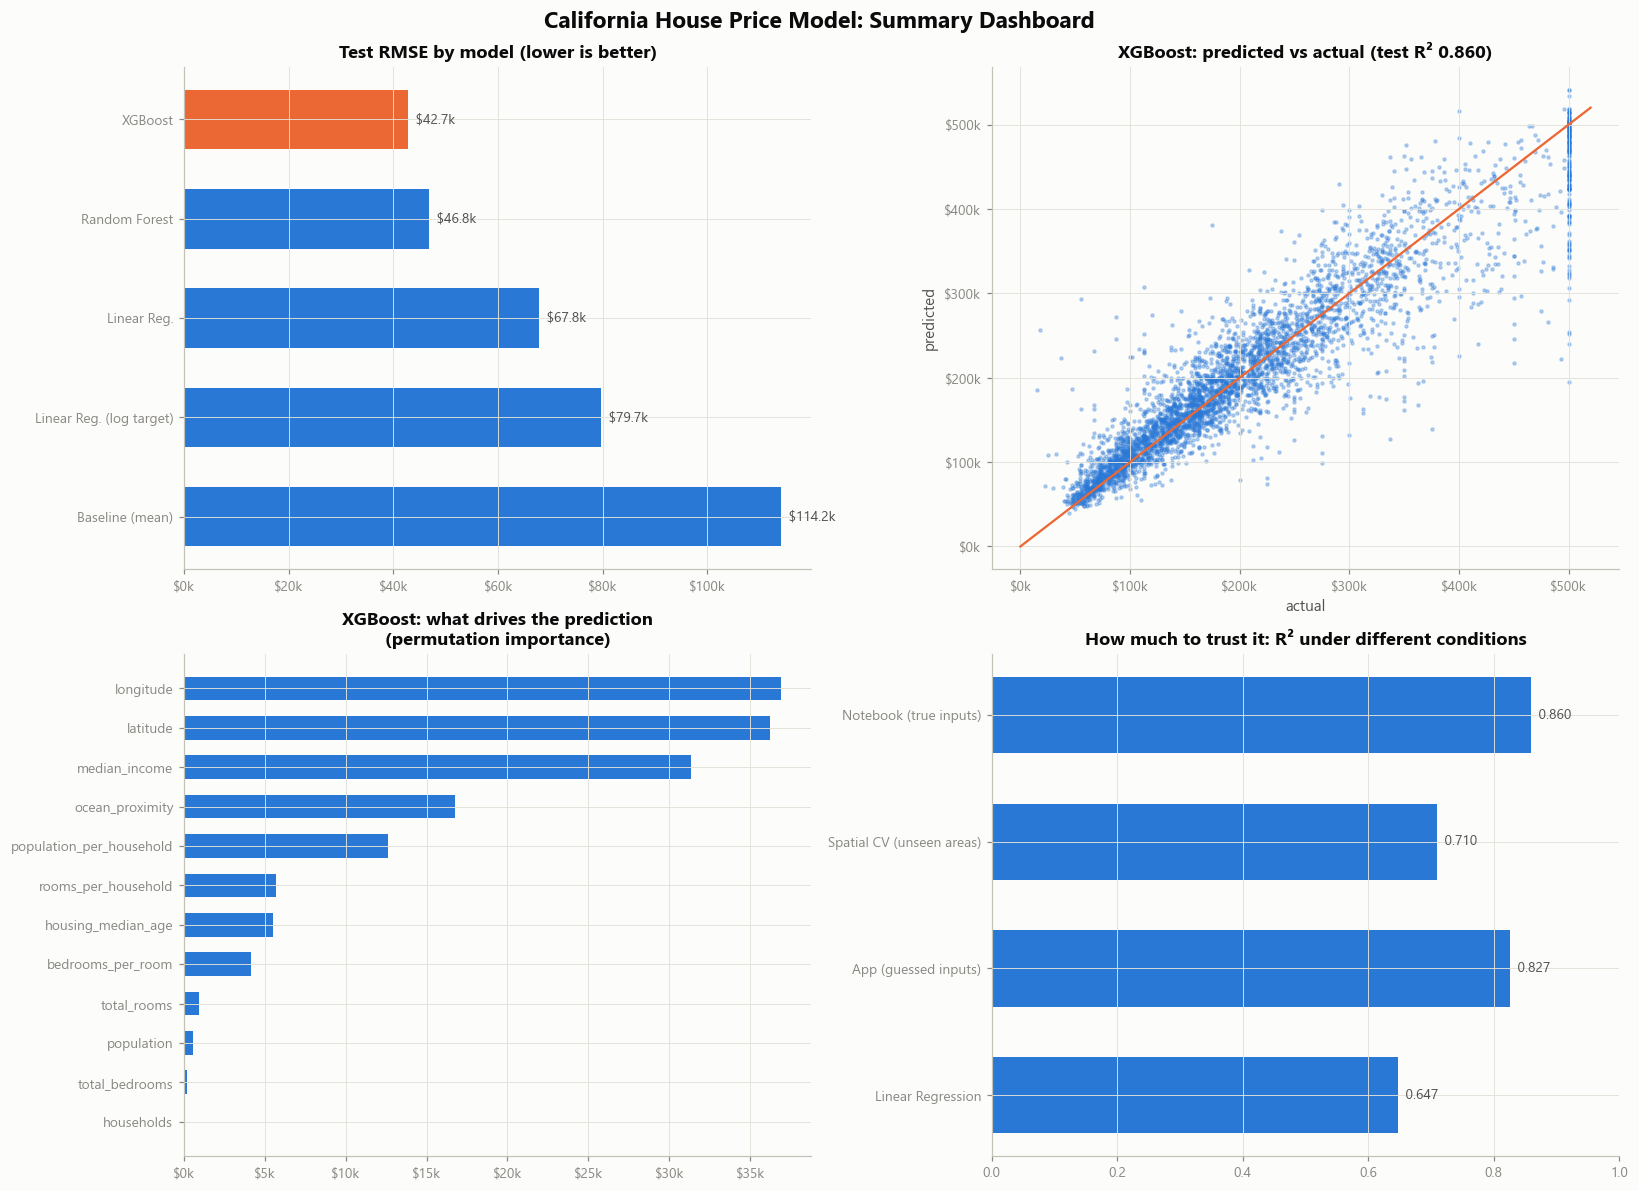

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

ax = axes[0, 0]
tt = test_table.sort_values("test RMSE", ascending=False)
ax.barh([n.replace("Linear Regression", "Linear Reg.") for n in tt.index], tt["test RMSE"],
        color=[ORANGE if n == BEST else BLUE for n in tt.index], height=0.6)
for i, v in enumerate(tt["test RMSE"]):
    ax.text(v, i, f"  ${v/1000:,.1f}k", va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(usd); ax.set_title("Test RMSE by model (lower is better)")

ax = axes[0, 1]
ax.scatter(y_test, test_pred[BEST], s=4, alpha=0.3, color=BLUE)
ax.plot([0, 520000], [0, 520000], color=ORANGE, linewidth=1.5)
ax.xaxis.set_major_formatter(usd); ax.yaxis.set_major_formatter(usd)
ax.set_xlabel("actual"); ax.set_ylabel("predicted")
ax.set_title(f"{BEST}: predicted vs actual (test R² {best_test['test R2']:.3f})")

ax = axes[1, 0]
pi = perm[BEST].sort_values()
ax.barh(pi.index, pi.values, color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(usd); ax.set_title(f"{BEST}: what drives the prediction\n(permutation importance)")

ax = axes[1, 1]
r = pd.Series({"Notebook (true inputs)": direct["R2"], "Spatial CV (unseen areas)": spatial_table.loc[BEST, "spatial GroupKFold R2"],
               "App (guessed inputs)": chain["R2"], "Linear Regression": test_table.loc["Linear Regression", "test R2"]})
ax.barh(r.index[::-1], r.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(r.values[::-1]):
    ax.text(v, i, f"  {v:.3f}", va="center", fontsize=9, color=INK2)
ax.set_xlim(0, 1); ax.set_title("How much to trust it: R² under different conditions")

fig.suptitle("California House Price Model: Summary Dashboard", fontsize=15, fontweight="bold", color=INK)
fig.tight_layout(); savefig(fig, "dashboard")

**Decision-oriented summary**

1. **Use a tree ensemble, not Linear Regression**, for price estimation. It cuts the error
   substantially, and the residual diagnostics confirm the linear form is wrong for this data.
2. **Income and coastal location explain most of the price**, and engineered per-household
   ratios add a modest extra signal.
3. **Trust the numbers less** for expensive coastal blocks (capped target), for regions far from
   the training data (spatial CV), and in the app, where income is guessed.
4. **Do not use for decisions about individuals.** Location-based pricing carries redlining and
   feedback-loop risks (§15).

## 17. Save the model and results

In [35]:
final = fitted[BEST]
if "device" in final.named_steps["model"].get_params():
    final.named_steps["model"].set_params(device="cpu")   # load and predict anywhere, GPU or not
joblib.dump(final, MODELS / "house_price_pipeline.joblib")

comparison = cv_table.join(test_table)
comparison.to_csv(REPORTS / "model_comparison.csv")
spatial_table.to_csv(REPORTS / "spatial_validation.csv")
perm.to_csv(REPORTS / "permutation_importance.csv")

report = {
    "best_model": BEST, "xgb_device": DEVICE,
    "tuning": {"rf_params": rf_search.best_params_, "rf_seconds": rf_time,
               "xgb_params": xgb_search.best_params_, "xgb_seconds": xgb_time, "xgb_fit_benchmark_s": bench},
    "test": test_table.to_dict(orient="index"),
    "cv": cv_table.to_dict(orient="index"),
    "spatial_cv": spatial_table.to_dict(orient="index"),
    "chained_app": {"true_inputs": direct, "helper_inputs": chain},
    "paired_ttest_rf_vs_xgb": {"t": float(t), "p": float(p)},
}
with open(REPORTS / "metrics.json", "w") as f:
    json.dump(report, f, indent=2, default=float)

q = data[["households", "population"]].quantile([0.25, 0.5, 0.75])
app_meta = {
    "best_model": BEST,
    "input_columns": list(X_train.columns),
    "presets": {  # block-group sizes for the app's neighbourhood selector (dataset quartiles)
        "Rural / small block": {"households": float(q.loc[0.25, "households"]), "population": float(q.loc[0.25, "population"])},
        "Typical block": {"households": float(q.loc[0.5, "households"]), "population": float(q.loc[0.5, "population"])},
        "Dense / large block": {"households": float(q.loc[0.75, "households"]), "population": float(q.loc[0.75, "population"])},
    },
    "test_metrics": direct, "app_metrics": chain,
    "max_click_distance_deg": 0.25,
}
with open(MODELS / "app_metadata.json", "w") as f:
    json.dump(app_meta, f, indent=2)
print("Saved:", sorted(str(p) for p in list(MODELS.glob("*")) + list(REPORTS.glob("*"))))

Saved: ['models\\app_metadata.json', 'models\\helper_metrics.json', 'models\\house_price_pipeline.joblib', 'models\\income_model.joblib', 'models\\ocean_model.joblib', 'reports\\metrics.json', 'reports\\model_comparison.csv', 'reports\\permutation_importance.csv', 'reports\\spatial_validation.csv']
